In [2]:
import json
import shutil
import time
from collections import Counter, defaultdict
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from ultralytics import YOLO

import costing as cs

print("torch", torch.__version__, "| cuda:", torch.cuda.is_available())

torch 2.11.0+cpu | cuda: False


In [ ]:
# switches
FAST = False        # True = a 1-epoch smoke test
SKIP_TRAIN = False  # True = reuse weights/best.pt and only redo evaluation and costing

# dataset and splits
WORKSPACE, PROJECT, VERSION = "cs614proj", "fire_smoke_detection-eskmo", 1
DATASET_DIR = Path("datasets") / f"{PROJECT}-v{VERSION}" 
SPLITS = ("train", "valid", "test")
POSITIVE_NAMES = {"fire", "smoke"}
AUGMENT_FACTOR = 3

# model and training parameters
BASE_MODEL = "yolo11n.pt"
if FAST:
    IMGSZ, EPOCHS, PATIENCE, BATCH, FRACTION = 320, 1, 1, 8, 0.1
else:
    IMGSZ, EPOCHS, PATIENCE, BATCH, FRACTION = 416, 25, 10, 16, 1.0
SEED = 0
DEVICE = 0 if torch.cuda.is_available() else "cpu"

# directories and files
WEIGHTS_DIR, RESULTS_DIR = Path("weights"), Path("results")
BEST_WEIGHTS = WEIGHTS_DIR / "best.pt"
WEIGHTS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

np.random.seed(SEED)
print(f"FAST={FAST}  SKIP_TRAIN={SKIP_TRAIN}  model={BASE_MODEL}  imgsz={IMGSZ}  "
      f"epochs={EPOCHS}  device={DEVICE}")

FAST=False  SKIP_TRAIN=True  model=yolo11n.pt  imgsz=416  epochs=25  device=cpu


In [4]:
from api_key import load_api_key

if not (DATASET_DIR / "data.yaml").exists():
    from roboflow import Roboflow

    key = load_api_key()
    key = key[0] if isinstance(key, (tuple, list)) else key
    rf = Roboflow(api_key=key)
    rf.workspace(WORKSPACE).project(PROJECT).version(VERSION).download(
        "yolov11", location=str(DATASET_DIR)
    )

cfg = yaml.safe_load(open(DATASET_DIR / "data.yaml"))
names = cfg["names"]
CLASS_NAMES = [names[i] for i in sorted(names)] if isinstance(names, dict) else list(names)
POS_IDS = {i for i, n in enumerate(CLASS_NAMES) if n.lower() in POSITIVE_NAMES}
assert len(POS_IDS) == len(POSITIVE_NAMES), f"expected {POSITIVE_NAMES} in {CLASS_NAMES}"


DATA_YAML = DATASET_DIR / "data_local.yaml"
yaml.safe_dump(
    {"path": str(DATASET_DIR.resolve()), "train": "train/images", "val": "valid/images",
     "test": "test/images", "names": CLASS_NAMES},
    open(DATA_YAML, "w"),
)
print("classes:", CLASS_NAMES, "| positive ids:", sorted(POS_IDS))

classes: ['None', 'fire', 'smoke'] | positive ids: [1, 2]


In [5]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def list_images(split):
    folder = DATASET_DIR / split / "images"
    return sorted(p for p in folder.iterdir() if p.suffix.lower() in IMG_EXT)


def read_labels(image_path):
    # [(class_id, x, y, w, h), ...]; a photo with no file, or an empty one, has no objects
    label = image_path.parent.parent / "labels" / f"{image_path.stem}.txt"
    rows = []
    if label.exists():
        for line in label.read_text().splitlines():
            parts = line.split()
            if len(parts) >= 5:
                rows.append((int(float(parts[0])), *map(float, parts[1:5])))
    return rows


def is_positive(image_path):
    return any(row[0] in POS_IDS for row in read_labels(image_path))


dataset_stats, table = {}, []
for split in SPLITS:
    images = list_images(split)
    instances, areas = Counter(), defaultdict(list)
    positive = only_none = empty = 0
    for path in images:
        labels = read_labels(path)
        ids = {row[0] for row in labels}
        for cls, _, _, w, h in labels:
            instances[CLASS_NAMES[cls]] += 1
            areas[CLASS_NAMES[cls]].append(w * h)
        if ids & POS_IDS:
            positive += 1
        elif ids:
            only_none += 1
        else:
            empty += 1
    entry = {
        "images": len(images),
        "positive_images": positive,
        "negative_images": only_none + empty,
        "negative_only_None_label": only_none,
        "negative_no_label": empty,
        "instances": dict(instances),
        "median_box_area_share": {c: float(np.median(a)) for c, a in areas.items()},
        "share_boxes_under_1pct_of_image": {
            c: float(np.mean(np.array(a) < 0.01)) for c, a in areas.items()
        },
    }
    if split == "train":
        entry["images_original_estimate"] = len(images) / AUGMENT_FACTOR
    dataset_stats[split] = entry
    row = {"split": split, "images": len(images), "positive": positive,
           "negative": only_none + empty}
    for c in CLASS_NAMES:
        row[f"n_{c}"] = instances.get(c, 0)
    for c in CLASS_NAMES:
        row[f"median_area_{c}"] = round(entry["median_box_area_share"].get(c, float("nan")), 4)
    table.append(row)

print(pd.DataFrame(table).to_string(index=False))
print(f"\ntrain is augmented {AUGMENT_FACTOR}x, so it holds about "
      f"{dataset_stats['train']['images'] / AUGMENT_FACTOR:.0f} original photos.")
print("valid and test are not augmented: those are real, distinct photos.")
json.dump(dataset_stats, open(RESULTS_DIR / "dataset_stats.json", "w"), indent=2)

split  images  positive  negative  n_None  n_fire  n_smoke  median_area_None  median_area_fire  median_area_smoke
train    1812       747      1065    1060    1380     1588               1.0            0.0792             0.0917
valid     301       117       184     184     199      209               1.0            0.0644             0.0906
 test     101        43        58      58      63       78               1.0            0.0776             0.0784

train is augmented 3x, so it holds about 604 original photos.
valid and test are not augmented: those are real, distinct photos.


In [6]:
started = time.perf_counter()
if SKIP_TRAIN and BEST_WEIGHTS.exists():
    print("SKIP_TRAIN is True and weights/best.pt exists: not training.")
    trained_now = False
else:
    model = YOLO(BASE_MODEL)
    model.train(
        data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, patience=PATIENCE,
        seed=SEED, device=DEVICE, fraction=FRACTION, project="runs", name="findfire",
        exist_ok=True, plots=True,
    )
    run_dir = Path(model.trainer.save_dir)
    best = run_dir / "weights" / "best.pt"
    shutil.copy(best if best.exists() else run_dir / "weights" / "last.pt", BEST_WEIGHTS)
    if (run_dir / "results.csv").exists():
        shutil.copy(run_dir / "results.csv", RESULTS_DIR / "train_log.csv")
    trained_now = True

import ultralytics

train_settings = {
    "trained_now": trained_now,
    "fast_mode": FAST,
    "base_model": BASE_MODEL,
    "epochs_requested": EPOCHS,
    "patience": PATIENCE,
    "imgsz": IMGSZ,
    "batch": BATCH,
    "fraction_of_train_used": FRACTION,
    "seed": SEED,
    "device": "cuda" if DEVICE == 0 else "cpu",
    "ultralytics": ultralytics.__version__,
    "torch": torch.__version__,
    "training_seconds": round(time.perf_counter() - started, 1),
    "weights": str(BEST_WEIGHTS),
}
if trained_now or not (RESULTS_DIR / "train_settings.json").exists():
    json.dump(train_settings, open(RESULTS_DIR / "train_settings.json", "w"), indent=2)
else:  # keep the record of the real training run, not of this re-evaluation
    train_settings = json.load(open(RESULTS_DIR / "train_settings.json"))
    IMGSZ = train_settings["imgsz"]
print(json.dumps(train_settings, indent=2))

SKIP_TRAIN is True and weights/best.pt exists: not training.
{
  "trained_now": true,
  "fast_mode": false,
  "base_model": "yolo11n.pt",
  "epochs_requested": 25,
  "patience": 10,
  "imgsz": 416,
  "batch": 16,
  "fraction_of_train_used": 1.0,
  "seed": 0,
  "device": "cpu",
  "ultralytics": "8.4.173",
  "torch": "2.11.0+cpu",
  "training_seconds": 5625.6,
  "weights": "weights\\best.pt"
}


In [7]:
log = pd.read_csv("results/train_log.csv")
log.columns = log.columns.str.strip()
print("epochs run:", len(log))
best = log.loc[log["metrics/mAP50(B)"].idxmax()]
print("best epoch:", int(best["epoch"]), "| val mAP50:", round(best["metrics/mAP50(B)"], 3))

epochs run: 25
best epoch: 24 | val mAP50: 0.607


In [8]:
model = YOLO(str(BEST_WEIGHTS))


CONFUSION_CONF = 0.25


def detection_metrics(m, split):
    split_arg = {"valid": "val"}.get(split, split)
    common = dict(data=str(DATA_YAML), split=split_arg, imgsz=IMGSZ, batch=BATCH,
                  device=DEVICE, verbose=False, project="runs", exist_ok=True)
    r = m.val(conf=0.001, plots=False, name=f"val_{split}", **common)
    rc = m.val(conf=CONFUSION_CONF, plots=True, name=f"val_{split}_matrix", **common)
    per_class = {}
    for i, class_id in enumerate(r.box.ap_class_index):
        p, rec, ap50, ap = r.box.class_result(i)
        per_class[r.names[int(class_id)]] = {
            "precision": float(p), "recall": float(rec),
            "ap50": float(ap50), "map50_95": float(ap),
        }
    head = [per_class[n] for n in per_class if n.lower() in POSITIVE_NAMES]
    labels = [r.names[i] for i in range(len(r.names))] + ["background"]
    return {
        "map50_all_classes": float(r.box.map50),
        "map50_95_all_classes": float(r.box.map),
        "map50_fire_smoke": float(np.mean([c["ap50"] for c in head])),
        "map50_95_fire_smoke": float(np.mean([c["map50_95"] for c in head])),
        "per_class": per_class,
        # rows = predicted, columns = true; the last index is "background"
        "confusion": np.asarray(rc.confusion_matrix.matrix).tolist(),
        "confusion_labels": labels,
        "confusion_conf": CONFUSION_CONF,
    }


detection = {split: detection_metrics(model, split) for split in ("valid", "test")}
detection["baselines"] = {
    "coco_zero_shot": {"map50_fire_smoke": 0.0, "map50_95_fire_smoke": 0.0,
                       "note": "COCO has no fire or smoke class; 'fire hydrant' is not fire."},
    "predict_nothing": {"map50_fire_smoke": 0.0, "map50_95_fire_smoke": 0.0},
}

rows = []
for cls, v in detection["test"]["per_class"].items():
    rows.append({"class": cls, "precision": v["precision"], "recall": v["recall"],
                 "AP50": v["ap50"], "mAP50-95": v["map50_95"]})
rows.append({"class": "fire+smoke (headline)", "precision": np.nan, "recall": np.nan,
             "AP50": detection["test"]["map50_fire_smoke"],
             "mAP50-95": detection["test"]["map50_95_fire_smoke"]})
print("TEST split, per class:")
print(pd.DataFrame(rows).round(3).to_string(index=False))

labels = detection["test"]["confusion_labels"]
print(f"\nbox-level confusion matrix on test at conf {CONFUSION_CONF} "
      "(rows = predicted, columns = true; background = no box / no object):")
print(pd.DataFrame(detection["test"]["confusion"], index=labels, columns=labels).round(0)
      .astype(int).to_string())

Ultralytics 8.4.173  Python-3.12.14 torch-2.11.0+cpu CPU (AMD Ryzen 7 7735HS with Radeon Graphics)
YOLO11n summary (fused): 100 layers, 2,582,737 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.30.1 ms, read: 67.731.0 MB/s, size: 49.0 KB)
val: Scanning C:\Users\sophi\Documents\Designing AI\daiist-assignment-2\datasets\fire_smoke_detection-eskmo-v1\valid\labels.cache... 301 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 301/301  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 2.2it/s 8.5s0.5s
                   all        301        592      0.655      0.574      0.598       0.46
Speed: 0.6ms preprocess, 19.5ms inference, 0.0ms loss, 0.9ms postprocess per image
Ultralytics 8.4.173  Python-3.12.14 torch-2.11.0+cpu CPU (AMD Ryzen 7 7735HS with Radeon Graphics)
YOLO11n summary (fused): 100 layers, 2,582,737 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 304.

In [9]:
for split in ("valid", "test"):
    print(split)
    print(pd.DataFrame(detection[split]["per_class"]).T.round(3))
print("headline AP50 fire+smoke: valid", round(detection["valid"]["map50_fire_smoke"], 3),
      "| test", round(detection["test"]["map50_fire_smoke"], 3))

valid
       precision  recall   ap50  map50_95
None       0.920   0.984  0.982     0.979
fire       0.532   0.417  0.465     0.227
smoke      0.512   0.321  0.348     0.173
test
       precision  recall   ap50  map50_95
None       0.948   0.983  0.987     0.982
fire       0.386   0.413  0.343     0.164
smoke      0.535   0.372  0.414     0.135
headline AP50 fire+smoke: valid 0.406 | test 0.379


In [10]:
def score_split(m, split, positive_names, batch=32):
    # One row per photo
    pos_ids = {int(i) for i, n in m.names.items() if n.lower() in positive_names}
    paths, rows = list_images(split), []
    for start in range(0, len(paths), batch):
        chunk = paths[start:start + batch]
        results = m.predict([str(p) for p in chunk], conf=0.001, imgsz=IMGSZ,
                            device=DEVICE, verbose=False)
        for path, res in zip(chunk, results):
            score, called = 0.0, ""
            for cls, conf in zip(res.boxes.cls.tolist(), res.boxes.conf.tolist()):
                if int(cls) in pos_ids and conf > score:
                    score, called = float(conf), m.names[int(cls)]
            rows.append({"split": split, "image": path.name, "truth": int(is_positive(path)),
                         "score": score, "called": called})
    return pd.DataFrame(rows)


coco = YOLO(BASE_MODEL)
matches = [n for n in coco.names.values() if any(w in n.lower() for w in ("fire", "smoke", "flame"))]
print("COCO classes that look like fire/smoke:", matches, "-> none is fire; zero-shot scores 0")

frames = []
for split in ("valid", "test"):
    frames.append(score_split(model, split, POSITIVE_NAMES).assign(system="finetuned"))
frames.append(score_split(coco, "test", set()).assign(system="coco_zero_shot"))
image_scores = pd.concat(frames, ignore_index=True)
image_scores.to_csv(RESULTS_DIR / "image_scores.csv", index=False)
print(image_scores.groupby(["system", "split"]).agg(photos=("truth", "size"),
      positive=("truth", "sum"), mean_score=("score", "mean")).round(3).to_string())


def populations(system, split):
    d = image_scores[(image_scores.system == system) & (image_scores.split == split)]
    return (np.sort(d[d.truth == 1].score.to_numpy()),
            np.sort(d[d.truth == 0].score.to_numpy()))

COCO classes that look like fire/smoke: ['fire hydrant'] -> none is fire; zero-shot scores 0
                      photos  positive  mean_score
system         split                              
coco_zero_shot test      101        43       0.000
finetuned      test      101        43       0.238
               valid     301       117       0.204


In [11]:
REF_CUT = 0.25
pos_ft, neg_ft = populations("finetuned", "test")
pos_zs, neg_zs = populations("coco_zero_shot", "test")
n_pos, n_neg = len(pos_ft), len(neg_ft)

systems = {
    "fine-tuned yolo": (pos_ft, neg_ft),
    "COCO zero-shot": (pos_zs, neg_zs),
    "always pass (majority/nothing)": (np.zeros(n_pos), np.zeros(n_neg)),
}
rows = []
for name, (p_s, n_s) in systems.items():
    c = cs.confusion_at(p_s, n_s, REF_CUT)
    rows.append({"system": name, "AUC": cs.auc(p_s, n_s), "recall": c["recall"],
                 "specificity": c["specificity"], "precision": c["precision"],
                 "accuracy": c["accuracy"], "TP": c["tp"], "FN": c["fn"],
                 "FP": c["fp"], "TN": c["tn"]})
comparison = pd.DataFrame(rows)
print(f"test photos: {n_pos} with fire/smoke, {n_neg} without, cut {REF_CUT}\n")
print(comparison.round(3).to_string(index=False))
print(f"\nmajority class on test is 'no fire' ({n_neg}/{n_pos + n_neg} = "
      f"{n_neg / (n_pos + n_neg):.1%} accuracy for doing nothing).")
detection["image_level_comparison"] = comparison.replace({np.nan: None}).to_dict("records")

test photos: 43 with fire/smoke, 58 without, cut 0.25

                        system   AUC  recall  specificity  precision  accuracy  TP  FN  FP  TN
               fine-tuned yolo 0.981    0.93        0.983      0.976     0.960  40   3   1  57
                COCO zero-shot 0.500    0.00        1.000        NaN     0.574   0  43   0  58
always pass (majority/nothing) 0.500    0.00        1.000        NaN     0.574   0  43   0  58

majority class on test is 'no fire' (58/101 = 57.4% accuracy for doing nothing).


In [12]:
PARAMS = cs.CostParams(
    # what an error costs (EUR per photo)
    c_fn=10_000.0,          # fire missed, found late
    c_tp=2_000.0,           # fire caught in time: it still did some damage
    c_tn=0.0,               # normal photo, correctly passed
    c_dispatch_fp=300.0,    # PLACEHOLDER: an engine sent out for nothing. Decide and justify.
    # one human review
    review_minutes=3.0,
    operator_eur_per_hour=12.0,
    overhead_per_review=0.40,
    human_recall=0.95,      # assumption: a person can miss a fire, but the operator is still used
    human_specificity=1.0,  # assumption: calling fire on an ordinary room photo is far rarer

    home_fire_per_year=0.001,   # 18,500 fires / 19.3 million households, rounded
    photos_per_day=4.0,         # per camera: morning, noon, evening, night
    cameras=2_000,              # an invented fleet size: a small startup in Madrid
    operator_productive_hours=7.0,
    max_operators=5.0,          # how many operators FindFire can staff
)
print(f"c_review         = EUR {PARAMS.c_review:.2f} per photo reviewed")
print(f"base rate        = {PARAMS.base_rate:.2e}  (1 photo in {1 / PARAMS.base_rate:,.0f})")
print(f"a miss costs     = EUR {PARAMS.c_fn - PARAMS.c_tp:,.0f} more than catching the fire in time")
print(f"photos per day   = {PARAMS.cameras * PARAMS.photos_per_day:,.0f}")

c_review         = EUR 1.00 per photo reviewed
base rate        = 6.85e-07  (1 photo in 1,460,000)
a miss costs     = EUR 8,000 more than catching the fire in time
photos per day   = 8,000


valid: 117 positive / 184 negative photos | test: 43 positive / 58 negative photos

cheapest threshold on valid: t* = 0.445 -> EUR 5.869 per 1,000 photos
  on test at that t*:  EUR 28.665 per 1,000 (raw, unsmoothed: EUR 20.459)
  do nothing:          EUR 6.849 per 1,000
  person checks all:   EUR 1,001.64 per 1,000
  share sent to review at t*: 0.270% of photos


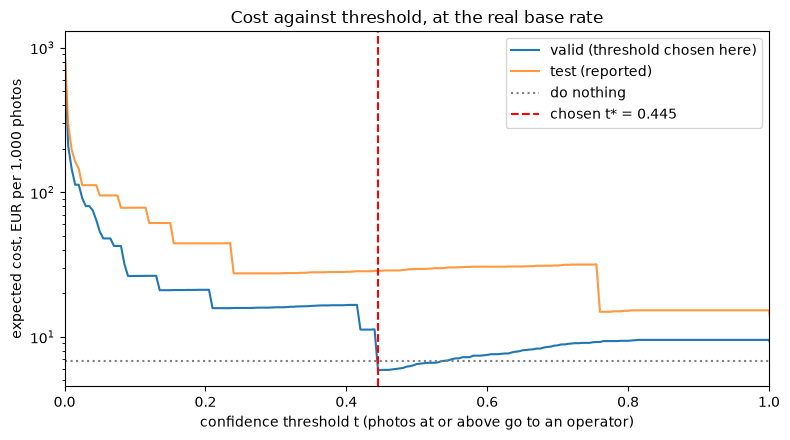

In [13]:
pos_v, neg_v = populations("finetuned", "valid")
pos_t, neg_t = populations("finetuned", "test")
print(f"valid: {len(pos_v)} positive / {len(neg_v)} negative photos | "
      f"test: {len(pos_t)} positive / {len(neg_t)} negative photos")

rows_v = cs.sweep(pos_v, neg_v, PARAMS, mode="operator")
rows_t = cs.sweep(pos_t, neg_t, PARAMS, mode="operator")
best_v = cs.best_threshold(rows_v)
T_STAR = best_v["low"]
at_test = cs.evaluate(pos_t, neg_t, T_STAR, cs.NEVER, PARAMS)
at_test_raw = cs.evaluate(pos_t, neg_t, T_STAR, cs.NEVER, PARAMS, smooth=False)
do_nothing = cs.evaluate(pos_v, neg_v, cs.NEVER, cs.NEVER, PARAMS)
all_human = cs.evaluate(pos_v, neg_v, 0.0, cs.NEVER, PARAMS)

print(f"\ncheapest threshold on valid: t* = {T_STAR:.3f} "
      f"-> EUR {best_v['cost_per_1000']:.3f} per 1,000 photos")
print(f"  on test at that t*:  EUR {at_test['cost_per_1000']:.3f} per 1,000 "
      f"(raw, unsmoothed: EUR {at_test_raw['cost_per_1000']:.3f})")
print(f"  do nothing:          EUR {do_nothing['cost_per_1000']:.3f} per 1,000")
print(f"  person checks all:   EUR {all_human['cost_per_1000']:,.2f} per 1,000")
print(f"  share sent to review at t*: {best_v['review_share']:.3%} of photos")

curve = pd.DataFrame({
    "threshold": [r["low"] for r in rows_v],
    "cost_per_1000_valid": [r["cost_per_1000"] for r in rows_v],
    "cost_per_1000_test": [r["cost_per_1000"] for r in rows_t],
    "review_share_valid": [r["review_share"] for r in rows_v],
    "operators_needed_valid": [r["operators_needed"] for r in rows_v],
})
curve.to_csv(RESULTS_DIR / "cost_sweep.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(curve.threshold, curve.cost_per_1000_valid, label="valid (threshold chosen here)")
ax.plot(curve.threshold, curve.cost_per_1000_test, label="test (reported)", alpha=0.8)
ax.axhline(do_nothing["cost_per_1000"], ls=":", c="grey", label="do nothing")
ax.axvline(T_STAR, ls="--", c="red", label=f"chosen t* = {T_STAR:.3f}")
ax.set_yscale("log")
ax.set_xlim(0, 1)
ax.set_xlabel("confidence threshold t (photos at or above go to an operator)")
ax.set_ylabel("expected cost, EUR per 1,000 photos")
ax.set_title("Cost against threshold, at the real base rate")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "cost_curve.png", dpi=150)
plt.show()

In [14]:
BAND_GRID = np.unique(np.round(np.concatenate([np.linspace(0, 1, 101), [cs.NEVER]]), 3))

free = cs.best_band(pos_v, neg_v, PARAMS, grid=BAND_GRID)
staffed = cs.best_band(pos_v, neg_v, PARAMS, grid=BAND_GRID, max_operators=PARAMS.max_operators)
alone = cs.best_threshold(cs.sweep(pos_v, neg_v, PARAMS, mode="alone"))


def describe(tag, r):
    top = "never" if r["high"] > 1 else f"{r['high']:.3f}"
    print(f"{tag:<26} low={r['low']:.3f}  high={top:<6} "
          f"EUR {r['cost_per_1000']:>8.3f}/1,000  review {r['review_share']:.3%}  "
          f"operators {r['operators_needed']:.2f}")


describe("band, unlimited staff", free)
describe("band, staffed (CHOSEN)", staffed)
describe("single cut, operator", best_v)
describe("single cut, no person", alone)

OPERATING_POINT = {
    "selected_on": "valid",
    "low": staffed["low"],
    "high": staffed["high"],
    "binary_threshold": T_STAR,
    "max_operators": PARAMS.max_operators,
    "unconstrained_low": free["low"],
    "unconstrained_high": free["high"],
    "valid": {k: staffed[k] for k in ("cost_per_1000", "review_share", "operators_needed",
                                      "reviews_per_day", "false_dispatches_per_day")},
}
json.dump(OPERATING_POINT, open(RESULTS_DIR / "operating_point.json", "w"), indent=2)

band, unlimited staff      low=0.450  high=never  EUR    5.913/1,000  review 0.270%  operators 0.15
band, staffed (CHOSEN)     low=0.450  high=never  EUR    5.913/1,000  review 0.270%  operators 0.15
single cut, operator       low=0.445  high=never  EUR    5.869/1,000  review 0.270%  operators 0.15
single cut, no person      low=1.010  high=never  EUR    6.849/1,000  review 0.000%  operators 0.00


In [15]:
pos, neg = pos_t, neg_t
designs = {
    "A. do nothing": cs.evaluate(pos, neg, cs.NEVER, cs.NEVER, PARAMS),
    "B. person checks every photo": cs.evaluate(pos, neg, 0.0, cs.NEVER, PARAMS),
    "C. model alone (best cut)": cs.evaluate(pos, neg, alone["low"], alone["low"], PARAMS),
    "D. model + review band": cs.evaluate(pos, neg, staffed["low"], staffed["high"], PARAMS),
}
table = pd.DataFrame({
    name: {
        "EUR per 1,000 photos": r["cost_per_1000"],
        "EUR per year (fleet)": r["cost_per_year"],
        "review share": r["review_share"],
        "reviews per day": r["reviews_per_day"],
        "operators needed": r["operators_needed"],
        "false dispatches per day": r["false_dispatches_per_day"],
        "fires missed per year": r["fires_missed_per_year"],
    } for name, r in designs.items()
}).T
print(f"fleet: {PARAMS.cameras:,} cameras x {PARAMS.photos_per_day:g} photos/day = "
      f"{PARAMS.cameras * PARAMS.photos_per_day:,.0f} photos/day\n")
print(table.to_string(float_format="{:,.3f}".format))
raw_d = cs.evaluate(pos, neg, staffed["low"], staffed["high"], PARAMS, smooth=False)
print(f"\ndesign D without smoothing: EUR {raw_d['cost_per_1000']:.3f} per 1,000")
print(f"staffable? D needs {designs['D. model + review band']['operators_needed']:.2f} "
      f"operators; FindFire can field {PARAMS.max_operators:g}.")
table.to_csv(RESULTS_DIR / "designs.csv")

fleet: 2,000 cameras x 4 photos/day = 8,000 photos/day

                              EUR per 1,000 photos  EUR per year (fleet)  review share  reviews per day  operators needed  false dispatches per day  fires missed per year
A. do nothing                                6.849            20,000.000         0.000            0.000             0.000                     0.000                  2.000
B. person checks every photo             1,001.644         2,924,800.000         1.000        8,000.000            57.143                     0.000                  0.100
C. model alone (best cut)                    6.849            20,000.000         0.000            0.000             0.000                     0.000                  2.000
D. model + review band                      28.665            83,702.260         0.025          203.393             1.453                     0.000                  0.683

design D without smoothing: EUR 20.459 per 1,000
staffable? D needs 1.45 operators; Find

In [16]:
rows = []
for c_fn in (4_000, 10_000, 50_000):
    for mult in (1, 3, 10):
        p2 = replace(PARAMS, c_fn=float(c_fn))
        sw = cs.sweep(pos_v, neg_v, p2, mode="operator", fp_mult=mult)
        b = cs.best_threshold(sw)
        nothing = cs.evaluate(pos_v, neg_v, cs.NEVER, cs.NEVER, p2)
        rows.append({"c_fn": c_fn, "false alarms x": mult, "best t": b["low"],
                     "EUR/1,000": b["cost_per_1000"], "do nothing": nothing["cost_per_1000"],
                     "system pays off": b["cost_per_1000"] < nothing["cost_per_1000"] - 1e-9})
sens_cost = pd.DataFrame(rows)
print(sens_cost.round(3).to_string(index=False))

rows = []
for fires in (0.0005, 0.001, 0.002):
    p2 = replace(PARAMS, home_fire_per_year=fires)
    b = cs.best_threshold(cs.sweep(pos_v, neg_v, p2, mode="operator"))
    nothing = cs.evaluate(pos_v, neg_v, cs.NEVER, cs.NEVER, p2)
    rows.append({"home fires per year": fires, "best t": b["low"],
                 "EUR/1,000": b["cost_per_1000"], "do nothing": nothing["cost_per_1000"],
                 "system pays off": b["cost_per_1000"] < nothing["cost_per_1000"] - 1e-9})
sens_rate = pd.DataFrame(rows)
print("\n" + sens_rate.to_string(index=False, float_format="{:.5g}".format))

 c_fn  false alarms x  best t  EUR/1,000  do nothing  system pays off
 4000               1   1.010      2.740       2.740            False
 4000               3   1.010      2.740       2.740            False
 4000              10   1.010      2.740       2.740            False
10000               1   0.445      5.869       6.849             True
10000               3   1.010      6.849       6.849            False
10000              10   1.010      6.849       6.849            False
50000               1   0.445     14.849      34.247             True
50000               3   0.445     20.254      34.247             True
50000              10   1.010     34.247      34.247            False

 home fires per year  best t  EUR/1,000  do nothing  system pays off
              0.0005    1.01     3.4247      3.4247            False
               0.001   0.445      5.869      6.8493             True
               0.002   0.445     9.0352      13.699             True


In [17]:
json.dump(detection, open(RESULTS_DIR / "metrics.json", "w"), indent=2)
json.dump(PARAMS.to_dict(), open(RESULTS_DIR / "params.json", "w"), indent=2)
sens_cost.to_csv(RESULTS_DIR / "sensitivity_cost.csv", index=False)
sens_rate.to_csv(RESULTS_DIR / "sensitivity_base_rate.csv", index=False)

print("weights :", BEST_WEIGHTS, f"({BEST_WEIGHTS.stat().st_size / 1e6:.1f} MB)")
for f in sorted(RESULTS_DIR.glob("*")):
    print("results :", f)
if FAST:
    print("\nFAST mode: this was a smoke test. Do NOT commit these weights or results.")
print("\nCommit weights/ and results/. The app needs both.")

weights : weights\best.pt (5.4 MB)
results : results\cost_curve.png
results : results\cost_sweep.csv
results : results\dataset_stats.json
results : results\designs.csv
results : results\image_scores.csv
results : results\metrics.json
results : results\operating_point.json
results : results\params.json
results : results\sensitivity_base_rate.csv
results : results\sensitivity_cost.csv
results : results\train_log.csv
results : results\train_settings.json

Commit weights/ and results/. The app needs both.
